In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import sys
sys.path.append("../src/utils/")
import enriched_adata as ea
from border_fit import ALL_SAMPLES, FIT_PALETTE, MIN_COMPONENT_SPOTS
from mpl_toolkits.axes_grid1 import make_axes_locatable

/home/woody/iwbn/iwbn007h/bosperrus/truncated_graphs/.pixi/envs/default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/woody/iwbn/iwbn007h/bosperrus/truncated_graphs/.pixi/envs/default/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
DATASET_TYPE_MARKERS = {"visium_demo": "o", "visium_custom": "s", "stomics_custom": "^", "Visium HD": "s", "STOmics": "^"}

In [3]:
PATIENT_PAIRS = [
    ("Pat1", "A02991D1"), ("Pat2", "A02994C6"), ("Pat3", "Y01087DD"), ("Pat4", "Y01084J8"),
]

# Part 1: Visium HD Demo (spot-based border)

In [4]:
results = []

In [5]:
for i, sample in enumerate(ALL_SAMPLES["name"].values):
    loader_type = ALL_SAMPLES["loader"].iloc[i]
    h5ad_path = ALL_SAMPLES["h5ad_path"].iloc[i]
    bin_size_um = ALL_SAMPLES["bin_size_um"].iloc[i]

    adata = ea.get_or_build_enriched_adata(sample, loader_type, h5ad_path, bin_size_um)
    ea.ensure_analysis_buffer(adata, bin_size_um, MIN_COMPONENT_SPOTS)
    blade_by_component = ea.ensure_blade_thresholds(adata, bin_size_um, MIN_COMPONENT_SPOTS)

    components = adata.obs["components"].to_numpy()
    per_component = adata.uns["analysis_buffer_fit"]["per_component"]
    print(f"{sample}: {len(per_component)} component(s) > {MIN_COMPONENT_SPOTS} spots")

    for label, info in per_component.items():
        member_mask = components == label

        # piecewise_linear_b comes back in um (bin_size_um was passed above) --
        # don't rescale it again below; bsp_thresh (grid-step units) does.
        bsp_thresh_um_value = info["params"].get("piecewise_linear_b")  # None if ConstantFit won
        bsp_thresh = bsp_thresh_um_value / bin_size_um if bsp_thresh_um_value is not None else None

        blade_thresh, blade_thresh_corrected = blade_by_component[label]
        pct_affected = float(adata.obs["analysis_buffer"].to_numpy()[member_mask].mean() * 100)

        results.append([
            sample, label, f"{sample}_{label}", info["n_spots"],
            blade_thresh, bsp_thresh, blade_thresh_corrected,
            bin_size_um,
            blade_thresh * bin_size_um if blade_thresh is not None else np.nan,
            bsp_thresh_um_value if bsp_thresh_um_value is not None else np.nan,
            blade_thresh_corrected * bin_size_um if blade_thresh_corrected is not None else np.nan,
            pct_affected,
        ])

    ea.save_enriched_adata(adata, sample)

breast_cancer: 3 component(s) > 1000 spots
pancreas: 1 component(s) > 1000 spots
colon_cancer_ff: 1 component(s) > 1000 spots
breast_cancer_tma: 36 component(s) > 1000 spots
Pat1: 1 component(s) > 1000 spots
Pat2: 3 component(s) > 1000 spots
Pat3: 4 component(s) > 1000 spots
Pat4: 2 component(s) > 1000 spots
A02991D1: 1 component(s) > 1000 spots
A02994C6: 5 component(s) > 1000 spots
Y01087DD: 5 component(s) > 1000 spots
Y01084J8: 4 component(s) > 1000 spots


In [6]:
results_df = pd.DataFrame(results, columns=[
    "sample", "component_rank", "component_label", "component_size",
    "blade_thresh", "bsp_thresh", "blade_thresh_corrected",
    "bin_size_um", "blade_thresh_um", "bsp_thresh_um", "blade_thresh_corrected_um",
    "pct_affected",
])
results_df = results_df.merge(ALL_SAMPLES[["name", "dataset_type"]], left_on="sample", right_on="name")
counts = results_df["sample"].value_counts()
results_df["num_components"] = results_df["sample"].apply(lambda x: counts[x])
results_df["component_size_um"] = results_df["component_size"] * results_df["bin_size_um"] ** 2  # spot count -> physical area (um^2); bin_size_um differs across technologies (8 vs. 10), so raw component_size isn't comparable

In [7]:
demo_results_df = results_df[results_df["dataset_type"] == "visium_demo"]

In [8]:
sample_pal = dict()
pair_colors = sns.color_palette("Paired", 9)
results_df["pair"] = None

for (i, pair) in enumerate(PATIENT_PAIRS):
    sample_pal[pair[0]] = pair_colors[2 * i]
    sample_pal[pair[1]] = pair_colors[2 * i + 1]
    mask = results_df["sample"].isin(pair)
    results_df.loc[mask, "pair"] = "_".join(pair)

sample_pal.update({s: sns.color_palette("Purples", 4)[i] for (i, s) in enumerate(demo_results_df["sample"].unique())})

# Part 2: paired Custom Visium HD + STOmics (no component matching -- see `notebooks/exploratory/stomics_visium_phase_matching.ipynb` for why)

In [9]:
part2_df = results_df[results_df["dataset_type"].isin(["visium_custom", "stomics_custom"])].copy()
part2_df["technology"] = part2_df["dataset_type"].map({"visium_custom": "Visium HD", "stomics_custom": "STOmics"})

In [10]:
figure2_df = demo_results_df.sort_values(["dataset_type", "sample", "component_rank"]).reset_index(drop=True)
component_spacing = 1
sample_gap = 2

x_pos = []
x = 0
previous_sample = None

for _, row in figure2_df.iterrows():
    if previous_sample is not None:
        x += sample_gap if row["sample"] != previous_sample else component_spacing
    x_pos.append(x)
    previous_sample = row["sample"]

x_pos = np.array(x_pos)
figure2_df["x_pos"] = x_pos

# Part 3: RNA diffusion outside the image mask

Pooled, component-free fits over RAW (whole-capture-area) data, computed on
a compute node by `src/utils/raw_diffusion.py` (see
`results/exploratory/raw_pooled_diffusion/`) rather than in this notebook --
per-component fits on the filtered/in-tissue-only data used to live here,
but nothing downstream needs them anymore (panel d's spot-based elbow
doesn't touch an image mask at all, so it stays on Part 1/2's own data).

In [11]:
import json
from pathlib import Path

# Panels e/f come from the pooled, component-free, raw-data fits
# (src/utils/raw_diffusion.py, run on a compute node -- see
# results/exploratory/raw_pooled_diffusion/).
RAW_POOLED_DIR = Path("../results/exploratory/raw_pooled_diffusion")
raw_pooled_df = pd.DataFrame([json.loads(p.read_text()) for p in sorted(RAW_POOLED_DIR.glob("*.json"))])

PATIENT_PAIR_LOOKUP = {s: "_".join(pair) for pair in PATIENT_PAIRS for s in pair}
raw_pooled_df["pair"] = raw_pooled_df["sample"].map(PATIENT_PAIR_LOOKUP)  # NaN for demo samples
raw_pooled_df["dataset_type"] = raw_pooled_df.apply(
    lambda row: "stomics_custom" if row["technology"] == "stomics"
                else ("visium_custom" if row["sample"] in PATIENT_PAIR_LOOKUP else "visium_demo"),
    axis=1,
)
raw_pooled_df["perc_outside"] = raw_pooled_df["diffusion_perc_outside"]
raw_pooled_df["alpha"] = raw_pooled_df["diffusion_alpha"]
raw_pooled_df["beta"] = raw_pooled_df["diffusion_beta"]
raw_pooled_df["1/beta"] = 1 / raw_pooled_df["beta"]

raw_pooled_paired_df = raw_pooled_df.dropna(subset=["pair"])  # panel e: paired samples only
raw_pooled_df

,diffusion_best_fit_type,diffusion_n_outside,diffusion_perc_outside,diffusion_alpha,diffusion_beta,elbow_best_fit_type,elbow_b_um,elbow_m,elbow_c,n_total_bins,n_counts_total,technology,sample,pair,dataset_type,perc_outside,alpha,beta,1/beta
0,Exponential Decay Fit,19494515,61.611943,5.645752,0.000071,Piecewise Linear Fit,1054.029386,-0.000266,1.511821,29098698,4.123169e+07,stomics,A02991D1,Pat1_A02991D1,stomics_custom,61.611943,5.645752,0.000071,14099.909973
1,Exponential Decay Fit,4033846,63.607087,4.262281,0.000020,Piecewise Linear Fit,256.686017,-0.000315,1.120860,6113612,6.666908e+06,stomics,A02994C6,Pat2_A02994C6,stomics_custom,63.607087,4.262281,0.000020,50777.615587
2,Exponential Decay Fit,56642407,50.232460,7.469459,0.000207,Piecewise Linear Fit,181.995200,-0.007534,2.973820,78213590,1.914490e+08,stomics,Y01084J8,Pat4_Y01084J8,stomics_custom,50.232460,7.469459,0.000207,4836.258373
3,Exponential Decay Fit,16531724,61.870956,6.701371,0.000108,Piecewise Linear Fit,115.067829,-0.016001,3.376174,19430783,4.184578e+07,stomics,Y01087DD,Pat3_Y01087DD,stomics_custom,61.870956,6.701371,0.000108,9274.571352
4,Exponential Decay Fit,7023616,5.929899,0.510574,0.006774,Piecewise Linear Fit,437.482996,-0.011599,5.158995,11222500,6.328765e+07,visium,Pat1,Pat1_A02991D1,visium_custom,5.929899,0.510574,0.006774,147.613033
5,Exponential Decay Fit,9976457,4.823862,0.336647,0.054526,Piecewise Linear Fit,63.308509,-0.054549,3.492581,11222500,1.454780e+07,visium,Pat2,Pat2_A02994C6,visium_custom,4.823862,0.336647,0.054526,18.339965
6,Exponential Decay Fit,9922676,2.264975,0.461253,0.028579,Piecewise Linear Fit,47.042042,-0.106317,5.037406,11222500,2.849643e+07,visium,Pat3,Pat3_Y01087DD,visium_custom,2.264975,0.461253,0.028579,34.990192
7,Exponential Decay Fit,5371028,3.062727,0.181546,0.003128,Piecewise Linear Fit,87.667572,-0.032600,3.144307,11222500,6.489621e+07,visium,Pat4,Pat4_Y01084J8,visium_custom,3.062727,0.181546,0.003128,319.666688
8,Exponential Decay Fit,7113049,1.252244,0.469105,0.002552,Piecewise Linear Fit,1234.665262,-0.006584,13.792388,30514576,6.190468e+08,visium,breast_cancer,NaN,visium_demo,1.252244,0.469105,0.002552,391.895218
9,Exponential Decay Fit,24001332,6.167675,0.220971,0.012319,Piecewise Linear Fit,126.559762,-0.027853,3.623415,30514576,6.173623e+07,visium,breast_cancer_tma,NaN,visium_demo,6.167675,0.220971,0.012319,81.172811


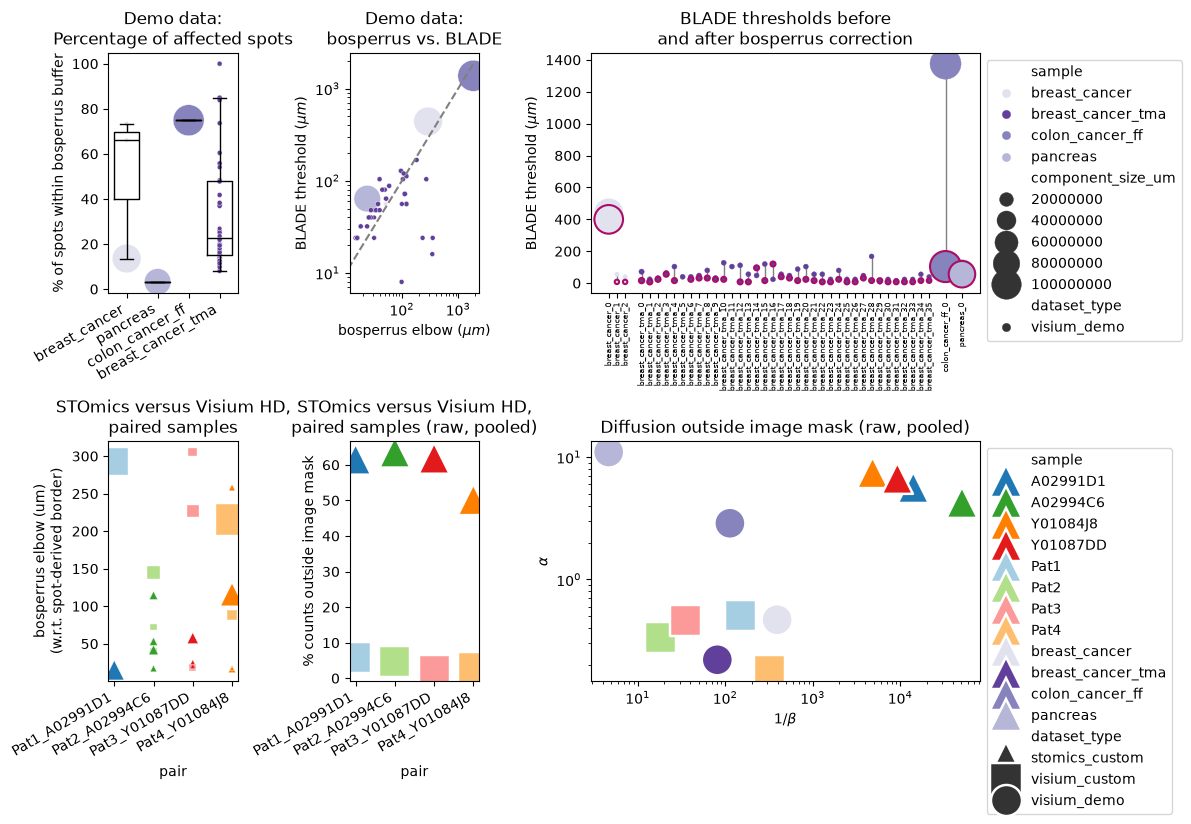

In [41]:
f, axs = plt.subplots(2, 3, figsize=(12, 8), width_ratios=[1, 1, 3])

# a: Demo data only. Which percentage of spots would need to be excluded according to bosperrus.
sns.boxplot(demo_results_df, x="sample", y="pct_affected", color="black", fill=False, showfliers=False, linewidth=1, ax=axs[0, 0])
sns.scatterplot(demo_results_df,  x="sample", y="pct_affected", style="dataset_type", hue="sample", size="component_size_um", markers=DATASET_TYPE_MARKERS, sizes=(10, 500), palette=sample_pal, ax=axs[0, 0], legend=False)
axs[0, 0].set_ylabel("% of spots within bosperrus buffer")
axs[0, 0].set_xlabel("")
axs[0, 0].set_title("Demo data:\nPercentage of affected spots")
axs[0, 0].set_xticks(axs[0, 0].get_xticks(), axs[0, 0].get_xticklabels(), rotation=30, ha="right")

# b: Demo data only. Agreement of BLADE and bosperrus.
sns.scatterplot(demo_results_df, y="blade_thresh_um", x="bsp_thresh_um", style="dataset_type", hue="sample", size="component_size_um", markers=DATASET_TYPE_MARKERS, sizes=(10, 500), palette=sample_pal, ax=axs[0, 1], legend=False)
max_val = np.max(demo_results_df[["blade_thresh_um", "bsp_thresh_um"]].values)
axs[0, 1].plot((0,max_val), (0, max_val), c="gray", ls="--")
axs[0, 1].set_title("Demo data:\nbosperrus vs. BLADE")
axs[0, 1].set_ylabel("BLADE threshold ($\\mu m$)")
axs[0, 1].set_xlabel("bosperrus elbow ($\\mu m$)")
axs[0, 1].set_yscale("log")
axs[0, 1].set_xscale("log")

# c: Demo data only. Bosperrus correction decreases BLADE identified buffer. 
for _, row in figure2_df.iterrows():
    axs[0, 2].plot([row["x_pos"], row["x_pos"]], [row["blade_thresh_um"], row["blade_thresh_corrected_um"]], color="gray", linewidth=1, zorder=0)

sns.scatterplot(data=figure2_df, x="x_pos", y="blade_thresh_um", hue="sample", style="dataset_type", markers=DATASET_TYPE_MARKERS, palette=sample_pal, sizes=(10, 500), size="component_size_um", edgecolor=None, legend=True, ax=axs[0, 2], zorder=2)
sns.scatterplot(data=figure2_df, x="x_pos", y="blade_thresh_corrected_um", hue="sample", style="dataset_type", markers=DATASET_TYPE_MARKERS, palette=sample_pal, sizes=(10, 500), size="component_size_um", edgecolor=FIT_PALETTE["Exponential Saturation Fit"], linewidth=1.5, legend=False, ax=axs[0, 2], zorder=2)

axs[0, 2].set_xticks(x_pos)
axs[0, 2].set_xticklabels(figure2_df["component_label"], rotation=90, fontsize=6)

axs[0, 2].set_xlabel("")
axs[0, 2].set_ylabel("BLADE threshold ($\\mu m$)")
axs[0, 2].set_title("BLADE thresholds before\nand after bosperrus correction")

#axs[0, 2].set_yscale("log")
sns.move_legend(axs[0, 2], "upper left", bbox_to_anchor=(1, 1))


# d: comparison of Visium HD and STOmics on paired samples via bosperrus elbows (spot-based border --
# no image mask involved, so this stays on the original per-component filtered-data pipeline). no 1:1
# matching of components possible, hence size encoding of components to somewhat facilitate comparison. 
de_size_min = part2_df["component_size_um"].min()
de_size_max = part2_df["component_size_um"].max()

sns.scatterplot(part2_df, x="pair", y="bsp_thresh_um", hue="sample", style="technology", palette=sample_pal, size="component_size_um", sizes=(10,500), ax=axs[1, 0], legend=False, size_norm=(de_size_min, de_size_max), markers=DATASET_TYPE_MARKERS, hue_order=list(sample_pal.keys()))
axs[1, 0].set_ylabel("bosperrus elbow (um)\n(w.r.t. spot-derived border)")
axs[1, 0].set_title("STOmics versus Visium HD,\npaired samples")
axs[1, 0].set_xticks(axs[1, 0].get_xticks(), axs[1, 0].get_xticklabels(), rotation=30, ha="right")

# e: comparison of Visium HD and STOmics on paired samples via percentage of RAW counts outside the
# image mask -- pooled per patient (no per-component split), from src/utils/raw_diffusion.py's
# compute-node run (whole-capture-area data, Space Ranger's own in_tissue / the counts-independent
# STOmics mask). No component_size_um anymore since there's one point per patient per technology.
raw_pooled_paired_df = raw_pooled_paired_df.sort_values("pair", axis=0)
sns.scatterplot(raw_pooled_paired_df, x="pair", y="perc_outside", hue="sample", style="dataset_type", palette=sample_pal, s=500, ax=axs[1, 1], legend=False, markers=DATASET_TYPE_MARKERS, hue_order=list(sample_pal.keys()))
axs[1, 1].set_ylabel("% counts outside image mask")
axs[1, 1].set_title("STOmics versus Visium HD,\npaired samples (raw, pooled)")
axs[1, 1].set_xticks(axs[1, 1].get_xticks(), axs[1, 1].get_xticklabels(), rotation=30, ha="right")


# f: comparison of Visium HD and STOmics diffusion outside of image mask via Exponential Decay model fit --
# now the same pooled raw-data fit as panel e, over all 12 samples (paired + demo). Filled marker: color=sample,
# shape=dataset_type, fixed size (no more component_size_um -- one point per sample now), black edge linewidth
# =perc_outside (wide 0.3-3.0pt range so it's actually visible).

sns.scatterplot(raw_pooled_df, x="1/beta", y="alpha", hue="sample", palette=sample_pal, s=500, style="dataset_type", ax=axs[1, 2], legend=True, markers=DATASET_TYPE_MARKERS)
sns.move_legend(axs[1, 2], "upper left", bbox_to_anchor=(1, 1))

axs[1, 2].set_xscale("log")
axs[1, 2].set_yscale("log")
axs[1, 2].set_ylabel("$\\alpha$")
axs[1, 2].set_xlabel("$1/\\beta$")
axs[1, 2].set_title("Diffusion outside image mask (raw, pooled)")

plt.tight_layout()
plt.show()

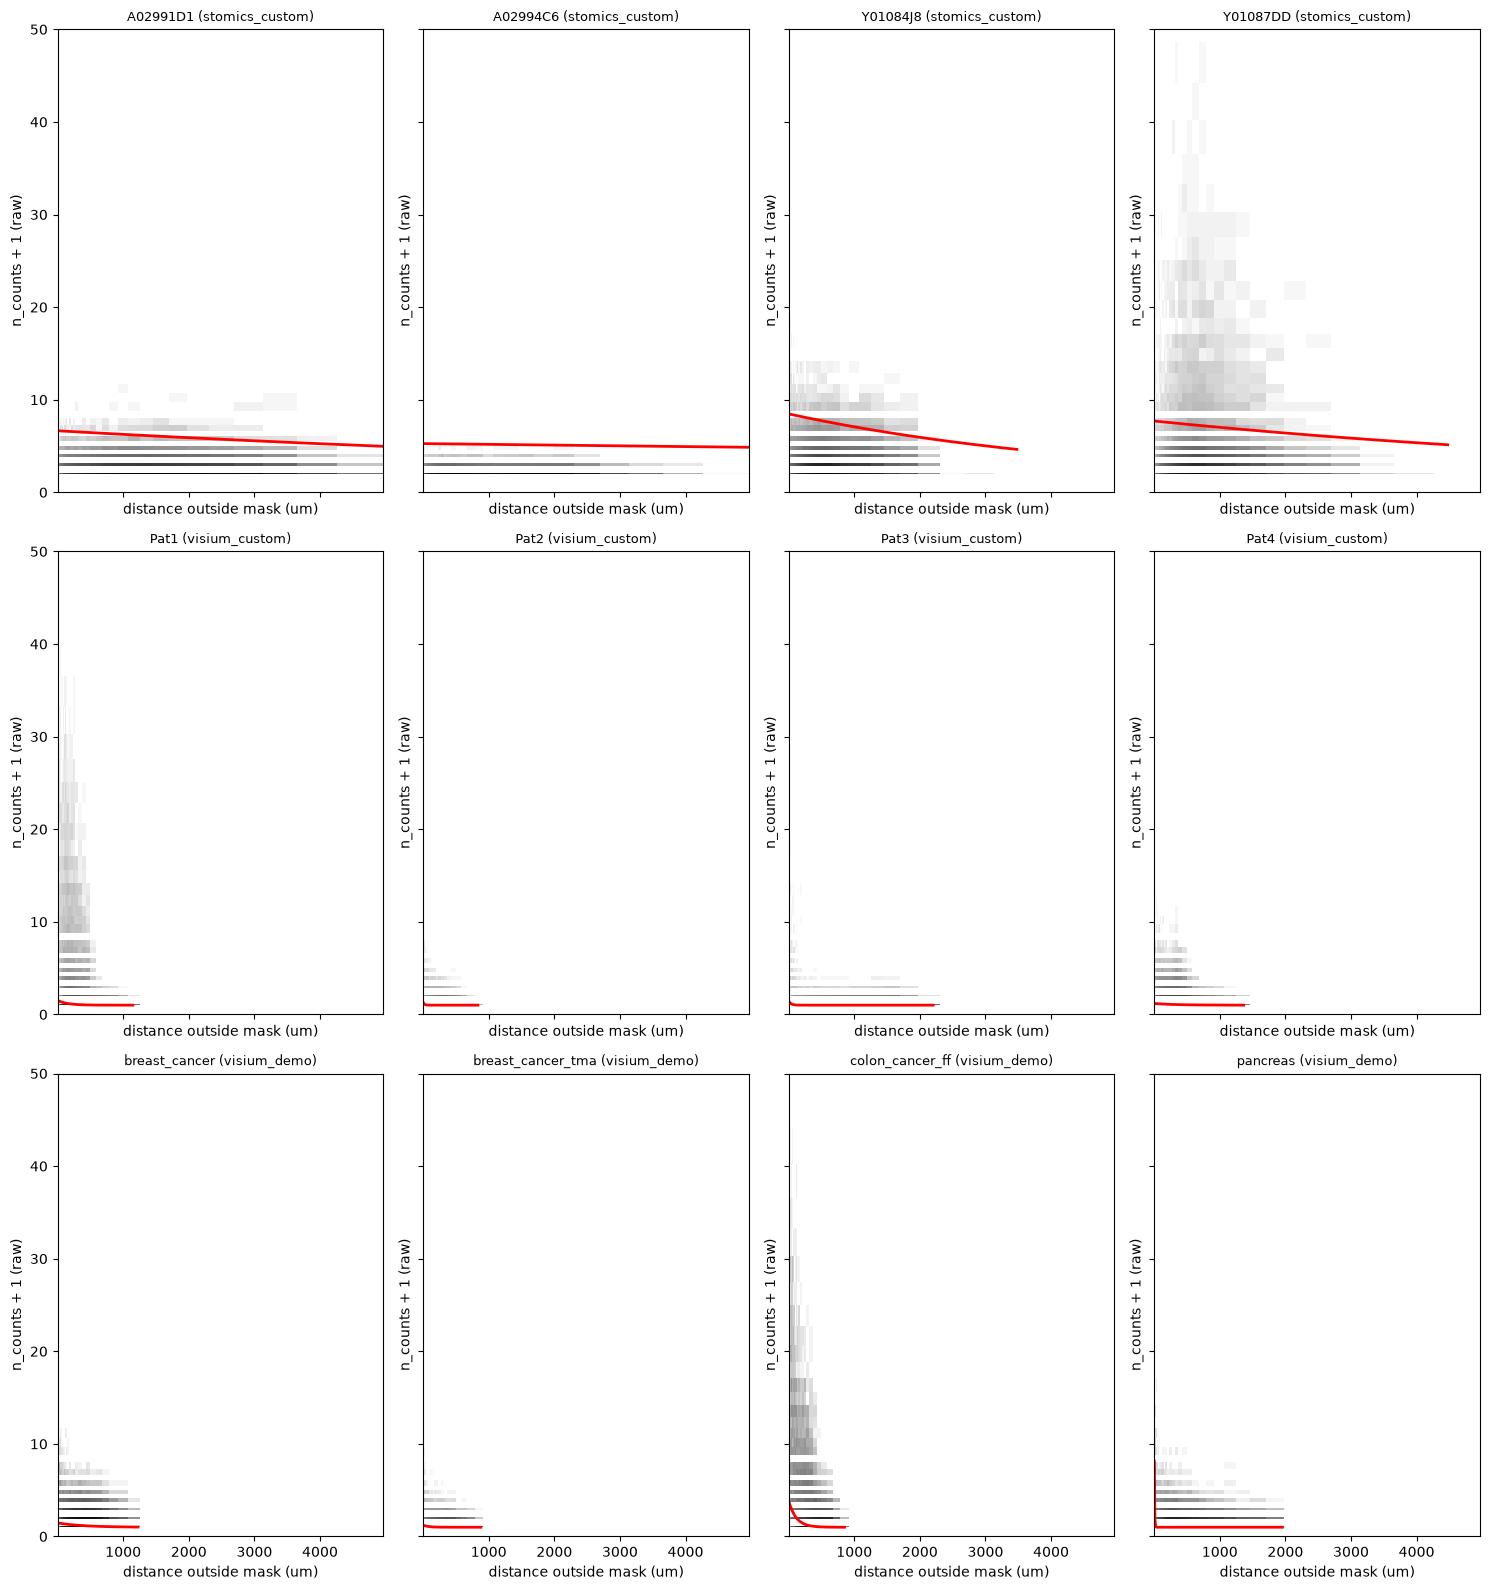

In [35]:
# One bosperrus.plot_fit per sample: the pooled diffusion fit (ConstantFit vs.
# ExponentialDecayFit, outside-mask points only -- same fit that produces
# panels e/f's numbers) over its own 2D histogram of raw (distance, n_counts)
# points. Points are a fixed random subsample (up to 300k, saved by
# raw_diffusion.py alongside the JSON) -- the full arrays run into the tens of
# millions and aren't needed for a density plot.
#
# Shared bin EDGES (not just a shared bin count) across all 12 subplots, so a
# given (distance, n_counts) cell means the same physical/count range
# everywhere -- ax.hist2d otherwise re-derives bin edges from each call's own
# data range, so a fixed bin count alone doesn't make bin WIDTH comparable
# across samples with very different ranges. Log-spaced, since both distance
# and n_counts span several orders of magnitude here, and it renders
# ExponentialDecayFit's a*exp(-b*d) as a straight line.
#
# n_counts+1 (not raw n_counts) for the histogram/curve: ~50% of outside-mask
# points have n_counts==0 (a real, common observation -- no RNA captured that
# far out), which the fit itself was computed on, but which a plain log-scale
# y-axis can't show at all (log(0) undefined) -- the +1 shift is the standard
# log1p treatment for count data, landing zeros visibly at y=1 instead of
# silently dropping half the evidence behind the fitted curve.
from bosperrus import plot_fit

all_distance, all_counts = [], []
for _, row in raw_pooled_df.iterrows():
    pts = np.load(RAW_POOLED_DIR / f"{row['technology']}_{row['sample']}_points.npz")
    outside = pts["distance"] > 0
    all_distance.append(pts["distance"][outside])
    all_counts.append(pts["n_counts"][outside])
all_distance, all_counts = np.concatenate(all_distance), np.concatenate(all_counts) + 1

N_BINS = 60
x_edges = np.logspace(np.log10(all_distance.min()), np.log10(all_distance.max()), N_BINS + 1)
y_edges = np.logspace(np.log10(all_counts.min()), np.log10(all_counts.max()), N_BINS + 1)
del all_distance, all_counts

fig, axes = plt.subplots(3, 4, figsize=(15, 16), sharex=True, sharey=True)
for ax, (_, row) in zip(axes.flat, raw_pooled_df.iterrows()):
    technology, sample = row["technology"], row["sample"]
    pts = np.load(RAW_POOLED_DIR / f"{technology}_{sample}_points.npz")
    distance, n_counts = pts["distance"], pts["n_counts"]
    outside = distance > 0

    if row["diffusion_best_fit_type"] == "Exponential Decay Fit":
        a, b = row["alpha"], row["beta"]
        predict_fn = lambda d, a=a, b=b: a * np.exp(-b * d) + 1  # +1 to match the n_counts+1 shift below
    else:  # ConstantFit baseline won instead
        c = n_counts[outside].mean() + 1
        predict_fn = lambda d, c=c: np.full_like(d, c)

    plot_fit(ax, distance[outside], n_counts[outside] + 1, predict_fn, bins=[x_edges, y_edges], line_kwargs={"color": "red"})
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_title(f"{sample} ({row['dataset_type']})", fontsize=9)
    ax.set_xlabel("distance outside mask (um)")
    ax.set_ylabel("n_counts + 1 (raw)")
    ax.set_ylim(0, 50)
plt.tight_layout()
plt.show()